In [1]:
# Diabetes Prediction using Machine Learning

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import os

# Find the dataset file
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/diabetes/diabetes.csv


In [3]:
df = pd.read_csv('/kaggle/input/diabetes/diabetes.csv')

print("Dataset loaded successfully!")
print("\nFirst 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

Dataset loaded successfully!

First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset Shape:
(768, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  ----- 

## Problem Statement

Diabetes is a major health condition that requires early identification and proper monitoring. The objective of this project is to develop a Machine Learning classification system that predicts whether a patient is diabetic or non-diabetic based on medical attributes such as glucose level, blood pressure, BMI, age and insulin level.

The Pima Indians Diabetes Dataset is used to train and evaluate multiple Machine Learning algorithms and compare their predictive performance.

In [6]:
# Check for missing values
print("Missing Values:")
print(df.isnull().sum())

# Check zero values in medical columns
columns_to_check = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

print("\nZero Values:")
for col in columns_to_check:
    print(col, ":", (df[col] == 0).sum())

# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Zero Values:
Glucose : 5
BloodPressure : 35
SkinThickness : 227
Insulin : 374
BMI : 11

Duplicate Rows: 0


In [7]:
# Create a copy of the original dataset
df_clean = df.copy()

# Columns where zero represents missing information
zero_columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

# Replace zero values with NaN
for col in zero_columns:
    df_clean[col] = df_clean[col].replace(0, np.nan)

# Fill missing values using median
for col in zero_columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("Data cleaning completed!")

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nZero values after cleaning:")
for col in zero_columns:
    print(col, ":", (df_clean[col] == 0).sum())

print("\nCleaned Dataset Shape:", df_clean.shape)

Data cleaning completed!

Missing values after cleaning:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Zero values after cleaning:
Glucose : 0
BloodPressure : 0
SkinThickness : 0
Insulin : 0
BMI : 0

Cleaned Dataset Shape: (768, 9)


In [9]:
# Statistical analysis of the dataset

print("Statistical Summary:")
print(df_clean.describe())

print("\nDiabetes Outcome Distribution:")
print(df_clean['Outcome'].value_counts())

print("\nPercentage Distribution:")
print(df_clean['Outcome'].value_counts(normalize=True) * 100)

Statistical Summary:
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  121.656250      72.386719      29.108073  140.671875   
std       3.369578   30.438286      12.096642       8.791221   86.383060   
min       0.000000   44.000000      24.000000       7.000000   14.000000   
25%       1.000000   99.750000      64.000000      25.000000  121.500000   
50%       3.000000  117.000000      72.000000      29.000000  125.000000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    32.455208                  0.471876   33.240885    0.348958  
std      6.875177                  0.331329   11.760232    0.476951  
min     18.200

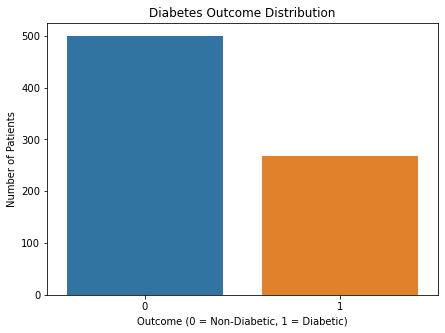

In [10]:
plt.figure(figsize=(7, 5))

sns.countplot(x='Outcome', data=df_clean)

plt.title('Diabetes Outcome Distribution')
plt.xlabel('Outcome (0 = Non-Diabetic, 1 = Diabetic)')
plt.ylabel('Number of Patients')

plt.show()

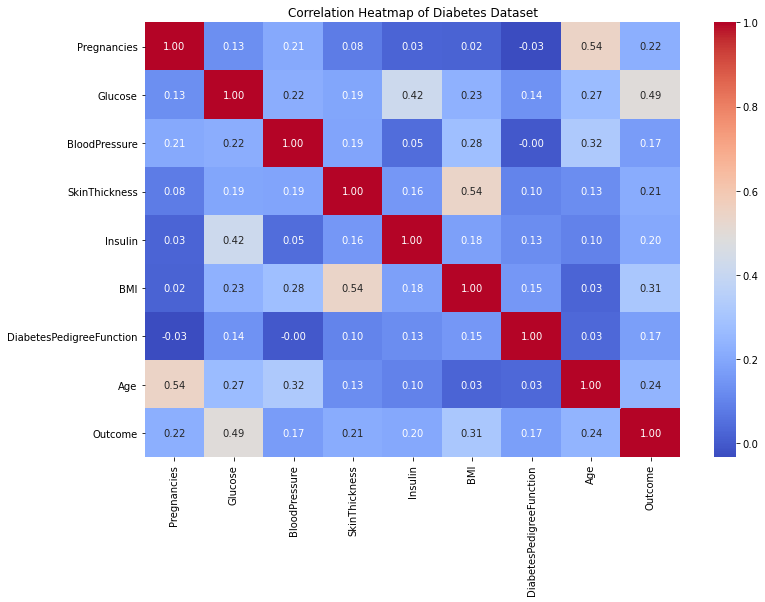

In [11]:
plt.figure(figsize=(12, 8))

correlation = df_clean.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Diabetes Dataset')
plt.show()

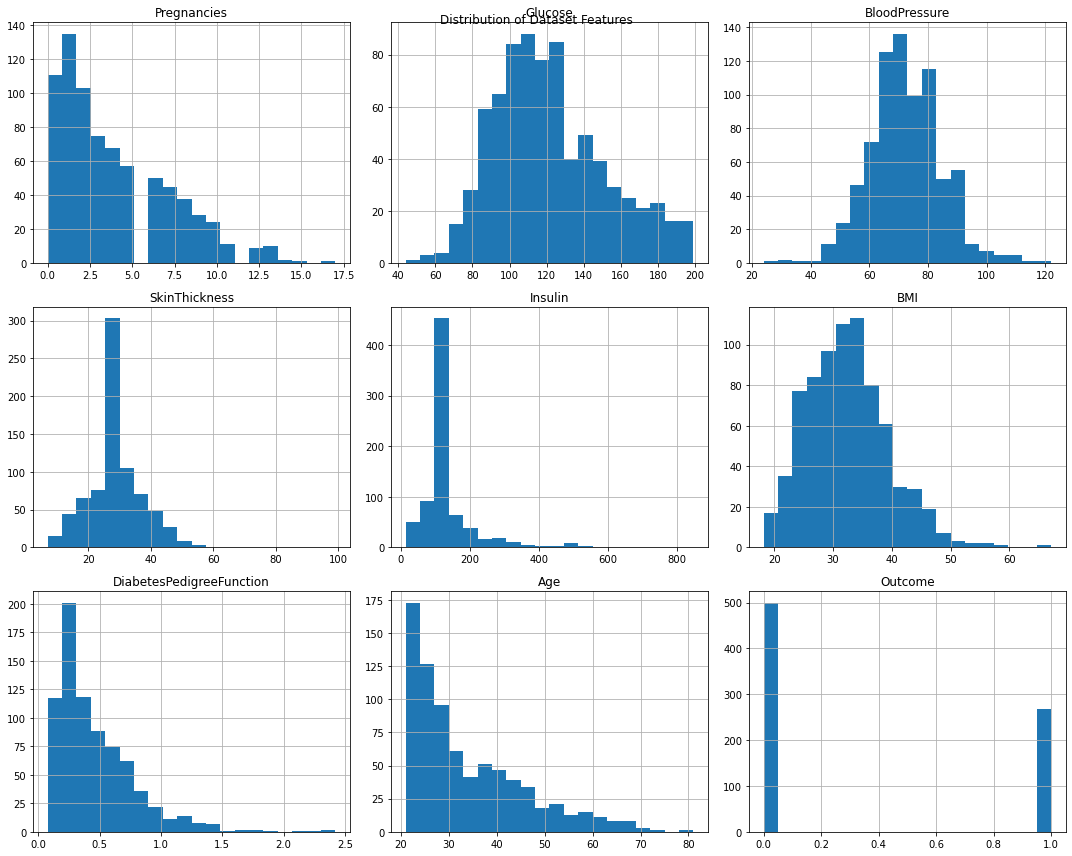

In [12]:
df_clean.hist(figsize=(15, 12), bins=20)

plt.suptitle('Distribution of Dataset Features')
plt.tight_layout()
plt.show()

In [13]:
# Feature Selection

X = df_clean.drop('Outcome', axis=1)
y = df_clean['Outcome']

print("Input Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print("Outcome")

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

Input Features:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Target Variable:
Outcome

X Shape: (768, 8)
y Shape: (768,)


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data: (614, 8)
Testing Data: (154, 8)

Training Target Distribution:
0    400
1    214
Name: Outcome, dtype: int64

Testing Target Distribution:
0    100
1     54
Name: Outcome, dtype: int64


In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")
print("Training scaled shape:", X_train_scaled.shape)
print("Testing scaled shape:", X_test_scaled.shape)

Feature scaling completed!
Training scaled shape: (614, 8)
Testing scaled shape: (154, 8)


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All Machine Learning algorithms imported successfully!")

All Machine Learning algorithms imported successfully!


In [17]:
# Create Machine Learning models

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel='linear')
}

# Store model results
results = []

trained_models = {}

# Train and evaluate each model
for name, model in models.items():

    if name in ["Logistic Regression", "KNN", "SVM"]:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    trained_models[name] = model

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    print("\nModel:", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print("Precision:", round(precision, 3))
    print("Recall:", round(recall, 3))
    print("F1-Score:", round(f1, 3))

print("\nAll five models trained successfully!")


Model: Logistic Regression
Accuracy: 70.78 %
Precision: 0.6
Recall: 0.5
F1-Score: 0.545

Model: Decision Tree
Accuracy: 68.18 %
Precision: 0.553
Recall: 0.481
F1-Score: 0.515

Model: Random Forest
Accuracy: 77.92 %
Precision: 0.727
Recall: 0.593
F1-Score: 0.653

Model: KNN
Accuracy: 75.32 %
Precision: 0.66
Recall: 0.611
F1-Score: 0.635

Model: SVM
Accuracy: 70.13 %
Precision: 0.591
Recall: 0.481
F1-Score: 0.531

All five models trained successfully!


In [18]:
# Compare all models

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
print(results_df.to_string(index=False))

MODEL PERFORMANCE COMPARISON
               Model  Accuracy  Precision    Recall  F1-Score
 Logistic Regression  0.707792   0.600000  0.500000  0.545455
       Decision Tree  0.681818   0.553191  0.481481  0.514851
       Random Forest  0.779221   0.727273  0.592593  0.653061
                 KNN  0.753247   0.660000  0.611111  0.634615
                 SVM  0.701299   0.590909  0.481481  0.530612


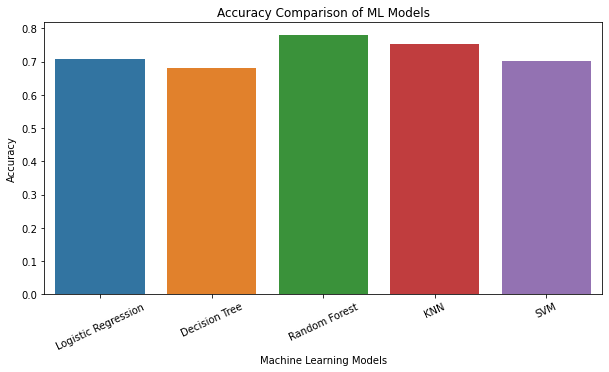

In [19]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy'
)

plt.title('Accuracy Comparison of ML Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy')
plt.xticks(rotation=25)

plt.show()

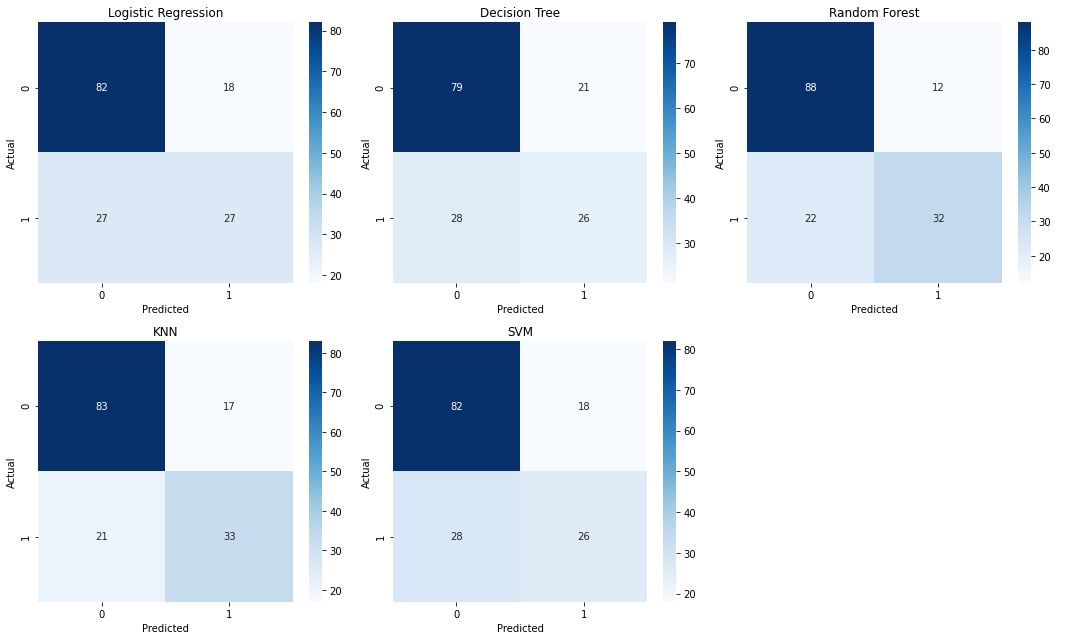

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (name, model) in zip(axes.flatten(), trained_models.items()):

    if name in ["Logistic Regression", "KNN", "SVM"]:
        y_pred = model.predict(X_test_scaled)
    else:
        y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

axes.flatten()[-1].axis('off')

plt.tight_layout()
plt.show()

In [21]:
best_model = results_df.sort_values(
    by='F1-Score',
    ascending=False
).iloc[0]

print("Best Performing Model:", best_model['Model'])
print("Accuracy:", round(best_model['Accuracy'] * 100, 2), "%")
print("Precision:", round(best_model['Precision'], 3))
print("Recall:", round(best_model['Recall'], 3))
print("F1-Score:", round(best_model['F1-Score'], 3))

Best Performing Model: Random Forest
Accuracy: 77.92 %
Precision: 0.727
Recall: 0.593
F1-Score: 0.653


In [22]:
# Classification reports for all models

for name, model in trained_models.items():

    if name in ["Logistic Regression", "KNN", "SVM"]:
        y_pred = model.predict(X_test_scaled)
    else:
        y_pred = model.predict(X_test)

    print("\n", "=" * 50)
    print("Classification Report:", name)
    print("=" * 50)

    print(classification_report(y_test, y_pred))


Classification Report: Logistic Regression
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154


Classification Report: Decision Tree
              precision    recall  f1-score   support

           0       0.74      0.79      0.76       100
           1       0.55      0.48      0.51        54

    accuracy                           0.68       154
   macro avg       0.65      0.64      0.64       154
weighted avg       0.67      0.68      0.68       154


Classification Report: Random Forest
              precision    recall  f1-score   support

           0       0.80      0.88      0.84       100
           1       0.73      0.59      0.65        54

    accuracy                           0.78       154
   macro

                    Feature  Importance
1                   Glucose    0.274086
5                       BMI    0.161903
6  DiabetesPedigreeFunction    0.125020
7                       Age    0.112985
4                   Insulin    0.091224
2             BloodPressure    0.083518
0               Pregnancies    0.080795
3             SkinThickness    0.070468


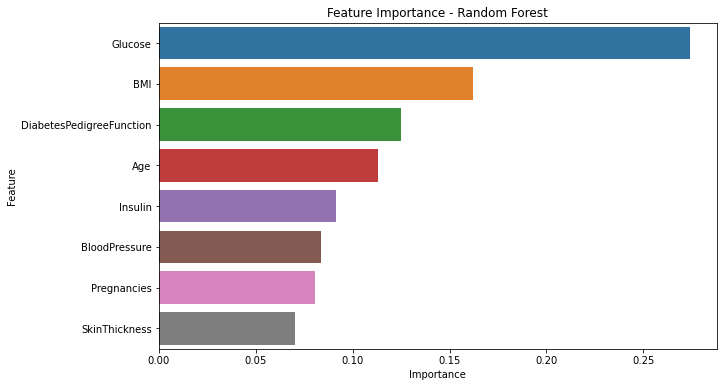

In [23]:
# Random Forest Feature Importance

rf_model = trained_models["Random Forest"]

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - Random Forest')
plt.show()

# Conclusion

The Diabetes Prediction project was implemented using the Pima Indians Diabetes Dataset.

Data preprocessing, cleaning, exploratory data analysis, feature selection and visualization were performed.

Five Machine Learning algorithms were implemented:
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. K-Nearest Neighbors
5. Support Vector Machine

The models were evaluated using Accuracy, Precision, Recall, F1-score and Confusion Matrix.

The performance of all five models was compared to identify the best-performing model based on the evaluation metrics.

This project demonstrates how Machine Learning can be applied to healthcare datasets for educational diabetes risk prediction.